In [1]:
# Run the hybrid tracker over one clip and store the causal track.
# Locked frames keep the posterior [x, y, vx, vy], its covariance,
# the one-step prediction that preceded the update, and the label.

import csv
from pathlib import Path
import sys

import cv2
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
import importlib
import tracking.efficient.model as efficient_model

importlib.reload(efficient_model)
from tracking.efficient.model import EfficientTracker

GAME, CLIP = "game1", "Clip1"

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
tracker.rules.start_at_uncertainty = True


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    """Model-resolution RGB, channel-first, for the baseline hooks."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    out_w, out_h = tracker.out_w, tracker.out_h
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def pack_track(frames: list[dict], steps: list[dict | None]) -> dict:
    """Dense arrays for frames after the filter locks.

    ``xy``, ``vel``, ``state``, and ``cov`` are the posterior. ``pred_*`` is
    the Gaussian from ``predict``, before the measurement update. The first
    locked frame has no prediction. ``label_xy`` is nan when that frame has
    no label coordinate.
    """
    locked = [i for i, step in enumerate(steps) if step is not None]
    if not locked:
        raise RuntimeError(f"{GAME}/{CLIP} never locked")

    n = len(locked)
    state = np.zeros((n, 4), dtype=np.float64)
    cov = np.zeros((n, 4, 4), dtype=np.float64)
    pred_state = np.full((n, 4), np.nan)
    pred_cov = np.full((n, 4, 4), np.nan)
    pred_xy = np.full((n, 2), np.nan)
    pred_std = np.full((n, 2), np.nan)
    z = np.full((n, 2), np.nan)
    r_std = np.full(n, np.nan)
    spread = np.full(n, np.nan)
    conf = np.full(n, np.nan)
    scale = np.zeros(n, dtype=np.float64)
    used = np.zeros(n, dtype=bool)
    label_xy = np.full((n, 2), np.nan)
    visibility = np.zeros(n, dtype=np.int64)
    status = np.zeros(n, dtype=np.int64)
    files = []
    source = []

    for j, i in enumerate(locked):
        step = steps[i]
        frame = frames[i]
        state[j] = step["state"]
        cov[j] = step["cov"]
        scale[j] = step["scale"]
        used[j] = bool(step["used"])
        r_std[j] = step["r_std"]
        spread[j] = step["spread"]
        conf[j] = step["conf"]
        visibility[j] = frame["visibility"]
        status[j] = frame["status"]
        files.append(frame["file"])
        source.append(step.get("source") or "")
        if frame["xy"] is not None:
            label_xy[j] = frame["xy"]
        if step["pred_state"] is not None:
            pred_state[j] = step["pred_state"]
            pred_cov[j] = step["pred_cov"]
            pred_xy[j] = step["pred"]
            pred_std[j] = step["pred_std"]
        if step["z"] is not None:
            z[j] = step["z"]

    pos_std = np.sqrt(np.maximum(np.diagonal(cov, axis1=1, axis2=2)[:, :2], 0.0))
    return {
        "index": np.asarray(locked, dtype=np.int64),
        "file": files,
        "state": state,
        "cov": cov,
        "xy": state[:, :2].copy(),
        "vel": state[:, 2:].copy(),
        "pos_std": pos_std,
        "pred_state": pred_state,
        "pred_cov": pred_cov,
        "pred_xy": pred_xy,
        "pred_std": pred_std,
        "z": z,
        "r_std": r_std,
        "spread": spread,
        "conf": conf,
        "scale": scale,
        "used": used,
        "source": source,
        "label_xy": label_xy,
        "visibility": visibility,
        "status": status,
    }


clip = load_clip(GAME, CLIP)
grays = [read_gray(frame["path"]) for frame in clip]
rgbs = [read_rgb(frame["path"]) for frame in clip]
steps = tracker.find_positions(grays, rgbs)
track = pack_track(clip, steps)

labeled = np.isfinite(track["label_xy"]).all(axis=1)
causal = np.linalg.norm(track["xy"] - track["label_xy"], axis=1)
causal = causal[labeled]
print(
    f"{GAME}/{CLIP}  {len(clip)} frames  "
    f"locked {len(track['index'])}  "
    f"{track['file'][0]} → {track['file'][-1]}"
)
print(
    f"state {track['state'].shape}  cov {track['cov'].shape}  "
    f"vel {track['vel'].shape}  pos_std {track['pos_std'].shape}"
)
print(
    f"causal posterior vs label  n={causal.size}  "
    f"mean={causal.mean():.2f} px  median={np.median(causal):.2f} px"
)


game1/Clip1  207 frames  locked 205  0002.jpg → 0206.jpg
state (205, 4)  cov (205, 4, 4)  vel (205, 2)  pos_std (205, 2)
causal posterior vs label  n=201  mean=4.19 px  median=1.14 px


position error vs label, px
labeled (visibility > 0)
  causal posterior        n= 201  mean=  4.19  median=  1.14  p90=  3.04
  smoothed                n= 201  mean=  2.80  median=  1.38  p90=  4.30
  one-step prediction     n= 200  mean=  9.13  median=  2.97  p90= 17.77
  mean smoothed - causal = -1.39 px
visible
  causal posterior        n= 183  mean=  3.51  median=  1.13  p90=  2.75
  smoothed                n= 183  mean=  2.64  median=  1.38  p90=  3.66
  one-step prediction     n= 182  mean=  8.52  median=  3.01  p90= 16.94
  mean smoothed - causal = -0.87 px
hard to see
  causal posterior        n=  17  mean=  5.95  median=  1.46  p90=  6.25
  smoothed                n=  17  mean=  2.46  median=  1.13  p90=  5.70
  one-step prediction     n=  17  mean= 10.41  median=  2.56  p90= 29.73
  mean smoothed - causal = -3.49 px
occluded
  causal posterior        n=   1  mean= 99.55  median= 99.55  p90= 99.55
  smoothed                n=   1  mean= 37.78  median= 37.78  p90= 37.78
  one-s

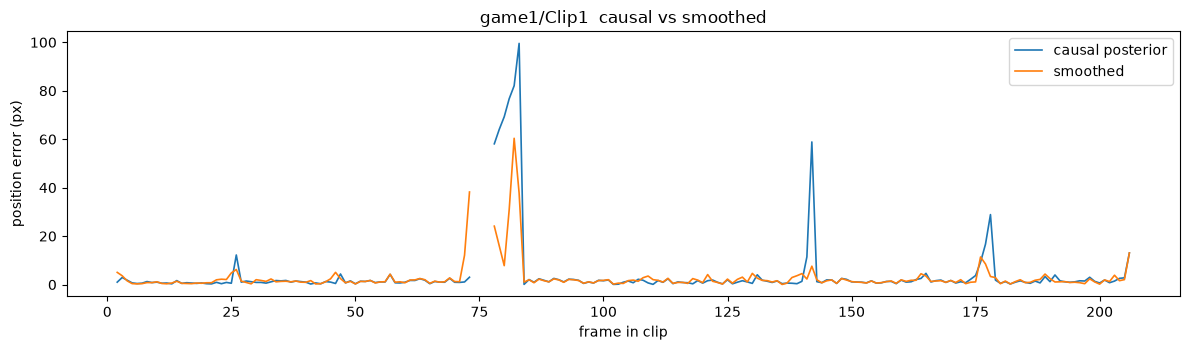

In [2]:
# RTS-smooth the finished track and score it against the causal posterior.
# Predict is linear in [x, y, vx, vy]. Process noise, misses, and the
# innovation scale bump are already inside the stored Gaussians, so this
# backward pass is the smoother for the filter that just ran.

import matplotlib.pyplot as plt
from tracking.ssm.base_akf.model import F

q_pos = float(tracker.ssm_cfg["q_pos"])
q_vel = float(tracker.ssm_cfg["q_vel"])

if not np.allclose(track["pred_state"][1:], track["state"][:-1] @ F.T, atol=1e-6):
    raise RuntimeError("stored prediction does not match F @ posterior")

scale = track["scale"][:-1]
process = np.zeros((len(scale), 4, 4), dtype=np.float64)
process[:, 0, 0] = q_pos
process[:, 1, 1] = q_pos
process[:, 2, 2] = q_vel * scale
process[:, 3, 3] = q_vel * scale
predicted_cov = F @ track["cov"][:-1] @ F.T + process
predicted_cov = 0.5 * (predicted_cov + np.swapaxes(predicted_cov, -1, -2))
if not np.allclose(track["pred_cov"][1:], predicted_cov, atol=1e-4):
    raise RuntimeError("stored predicted covariance does not match predict()")


def rts_smooth(track: dict) -> dict:
    """Rauch–Tung–Striebel means and covariances, aligned with ``track``."""
    n = len(track["state"])
    mean = track["state"].copy()
    cov = track["cov"].copy()
    for k in range(n - 2, -1, -1):
        filtered = cov[k].copy()
        predicted = track["pred_cov"][k + 1]
        gain = np.linalg.solve(predicted, (filtered @ F.T).T).T
        mean[k] = mean[k] + gain @ (mean[k + 1] - track["pred_state"][k + 1])
        updated = filtered + gain @ (cov[k + 1] - predicted) @ gain.T
        updated = 0.5 * (updated + updated.T)
        vals, vecs = np.linalg.eigh(updated)
        cov[k] = (vecs * np.maximum(vals, 0.0)) @ vecs.T
    last = 0.5 * (cov[-1] + cov[-1].T)
    vals, vecs = np.linalg.eigh(last)
    cov[-1] = (vecs * np.maximum(vals, 0.0)) @ vecs.T
    pos_std = np.sqrt(np.maximum(np.diagonal(cov, axis1=1, axis2=2)[:, :2], 0.0))
    return {
        "state": mean,
        "cov": cov,
        "xy": mean[:, :2].copy(),
        "vel": mean[:, 2:].copy(),
        "pos_std": pos_std,
    }


def position_error(xy: np.ndarray) -> np.ndarray:
    err = np.linalg.norm(xy - track["label_xy"], axis=1)
    err[~np.isfinite(track["label_xy"]).all(axis=1)] = np.nan
    return err


def summarize(name: str, err: np.ndarray, mask: np.ndarray) -> None:
    values = err[mask & np.isfinite(err)]
    if values.size == 0:
        print(f"  {name:22}  n=   0")
        return
    print(
        f"  {name:22}  n={values.size:4d}  "
        f"mean={values.mean():6.2f}  median={np.median(values):6.2f}  "
        f"p90={np.percentile(values, 90):6.2f}"
    )


smooth = rts_smooth(track)
causal_err = position_error(track["xy"])
smooth_err = position_error(smooth["xy"])
pred_err = position_error(track["pred_xy"])

labeled = np.isfinite(track["label_xy"]).all(axis=1)
groups = [
    ("labeled (visibility > 0)", labeled),
    ("visible", track["visibility"] == 1),
    ("hard to see", track["visibility"] == 2),
    ("occluded", track["visibility"] == 3),
    ("detector used", labeled & track["used"]),
    ("detector miss", labeled & ~track["used"]),
]
print("position error vs label, px")
for title, mask in groups:
    if not np.any(mask):
        continue
    print(title)
    summarize("causal posterior", causal_err, mask)
    summarize("smoothed", smooth_err, mask)
    summarize("one-step prediction", pred_err, mask)
    both = mask & np.isfinite(causal_err) & np.isfinite(smooth_err)
    if np.any(both):
        delta = float(np.mean(smooth_err[both] - causal_err[both]))
        print(f"  mean smoothed - causal = {delta:+.2f} px")

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(track["index"], causal_err, color="C0", lw=1.2, label="causal posterior")
ax.plot(track["index"], smooth_err, color="C1", lw=1.2, label="smoothed")
ax.set_xlabel("frame in clip")
ax.set_ylabel("position error (px)")
ax.set_title(f"{GAME}/{CLIP}  causal vs smoothed")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
